# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [19]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [17]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [18]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [23]:
#revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [24]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [25]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [26]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [27]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean().round(4))  # proporción (0 a 1)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.0000
first_name    0.0000
last_name     0.0000
age           0.0000
city          0.1172
reg_date      0.0000
plan          0.0000
churn_date    0.8835
dtype: float64


In [28]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean().round(4))

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.0000
user_id     0.0000
type        0.0000
date        0.0012
duration    0.5519
length      0.4474
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
users

city: 469 nulos (11.72%)
churn_date: 3,534 nulos (88.35%)

usage

date: 50 nulos (0.12%)
duration: 22,076 nulos (55.19%)
length: 17,896 nulos (44.74%)
- Indica qué harías: ¿imputar, eliminar, ignorar?


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.


In [29]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


La columna user_id tiene 4,000 valores que van de 10000 a 13999, consecutivos y sin valores inválidos ni sentinels.
La columna age tiene un mínimo de -999, que es un sentinel de dato faltante. Distorsiona la media (33.7 frente a una mediana de 47) y la desviación estándar (123.2). El máximo de 79 es razonable. Lo reemplazaría por la mediana en el paso 3.1, porque la mediana no se ve afectada por valores extremos.

In [30]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


Las columnas id y user_id no tienen valores inválidos: id va de 1 a 40000 de forma consecutiva y user_id va de 10000 a 13999, el mismo rango que en users.
La columna duration no tiene negativos. Tiene ceros (que pueden ser llamadas sin conexión) y un máximo de 120 muy por encima del percentil 75 (6.99), lo que sugiere sesgo a la derecha y posibles outliers.
La columna length no tiene negativos. Tiene ceros y un máximo de 1490 muy por encima del percentil 75 (64), posible outlier que se revisará en el paso 5.2.

In [31]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(f"--- {col} ---")
    print(users[col].value_counts(dropna=False))
    print()



--- city ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

--- plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64



La columna city tiene seis ciudades válidas, 469 nulos y 96 registros con “?”, que es un sentinel de dato desconocido. Lo reemplazaría por nulo en el paso 3.1, porque no se puede inferir la ciudad y así se trata igual que los demás faltantes.
La columna plan solo tiene dos categorías, Basico (2,595) y Premium (1,405), sin errores de escritura ni nulos. No requiere limpieza.

In [33]:

# explorar columna categórica de usage
usage['type'].value_counts(dropna=False) # completa el código


text    22092
call    17908
Name: type, dtype: int64

La columna type solo tiene dos categorías, text (22,092) y call (17,908), sin nulos, errores de escritura ni valores inesperados. No requiere limpieza.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
¿En qué columnas encontraste valores inválidos o sentinels? En users['age'], con el valor -999 (sentinel de dato faltante), y en users['city'], con “?” en 96 registros. En usage no hay sentinels: duration y length tienen ceros y valores máximos altos (120 y 1490), pero son atípicos, no inválidos.
¿Qué acción tomarías? En age, reemplazar -999 por la mediana, porque la mediana no se ve afectada por valores extremos. En city, reemplazar “?” por nulo (pd.NA), porque no se puede inferir la ciudad y así se trata igual que los demás faltantes. Los valores extremos de usage se revisarán en el paso de outliers.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [41]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [42]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [43]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En reg_date, los años van de 2022 a 2026: 1,314 registros en 2022, 1,316 en 2023 y 1,330 en 2024, pero 40 registros tienen año 2026, que es una fecha imposible porque los datos solo llegan hasta 2024 (1% de las filas).
En date, los 39,950 registros válidos corresponden a 2024 y hay 50 nulos (0.12%), los mismos que ya existían antes de la conversión. No hay años fuera de rango.

In [44]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()

2024.0    39950
NaN          50
Name: date, dtype: int64

En date, los 39,950 registros válidos corresponden todos al año 2024, dentro del periodo esperado. Hay 50 nulos (0.12%), los mismos que ya existían antes de la conversión, por lo que no hay fechas imposibles. Los dejaría como nulos, porque son muy pocos y no conviene inventar fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
-Aparecen años imposibles? Sí, en reg_date: 40 registros con año 2026. En date no.
¿Qué harías con ellas? Marcarlas como nulas (pd.NA), porque no se puede saber la fecha real de registro y es más seguro tratarlas como faltantes que inventar un valor. Esto se hace en el paso 3.1.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [45]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)
# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [46]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [47]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [48]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [49]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Los nulos en duration y length son MAR, porque dependen de la columna type:

duration: es nula en 99.93% de los registros text y en 0% de los call. Los mensajes de texto no tienen duración.
length: es nula en 99.93% de los registros call y en 0% de los text. Las llamadas no tienen longitud de mensaje.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [50]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)  # conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int)  # conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
        }).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [51]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [52]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [53]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [54]:
# Distribución porcentual del tipo de plan
(user_profile['plan'].value_counts(normalize=True) * 100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

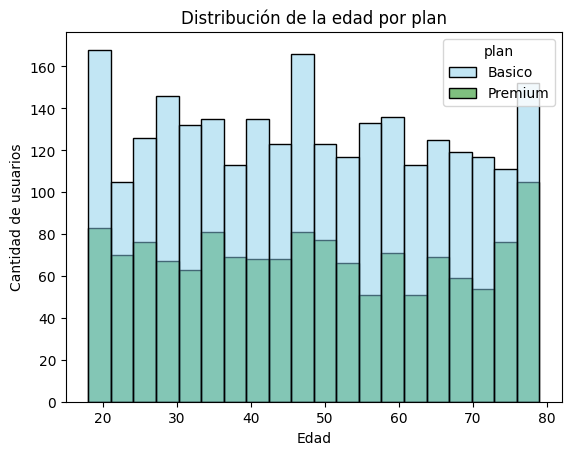

In [55]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], bins=20)
plt.title('Distribución de la edad por plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
Distribución: aproximadamente uniforme, con edades de 18 a 79 años y sin sesgo marcado.
Por plan: Basico y Premium tienen una distribución de edad muy parecida, sin un grupo de edad que prefiera un plan. No existe algún patrón claro entre la edad y el tipo de plan. Basico tiene más usuarios en todos los rangos porque es el plan más grande (64.88% de la base).

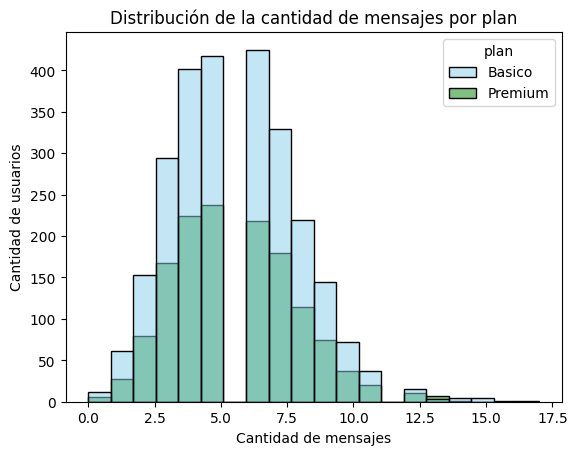

In [56]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], bins=20)
plt.title('Distribución de la cantidad de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
Distribución: sesgada a la derecha. La mayoría de los usuarios envía entre 2 y 9 mensajes, con un pico entre 4 y 7, y una cola corta de usuarios que envían más de 12.
Por plan: Basico y Premium tienen la misma forma de distribución y se concentran en los mismos valores. No existe algún patrón claro entre el plan y la cantidad de mensajes. Premium se ve más bajo solo porque tiene menos usuarios.

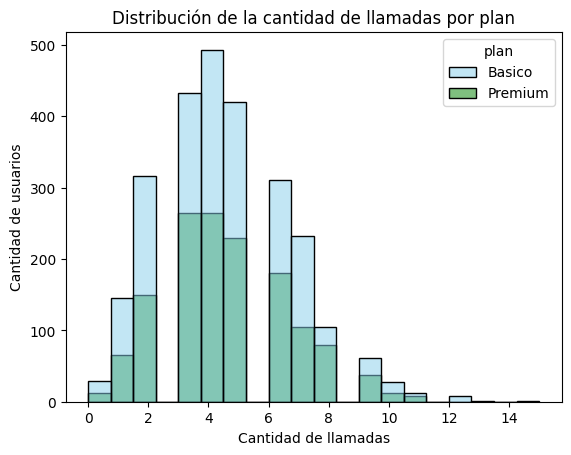

In [57]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], bins=20)
plt.title('Distribución de la cantidad de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
Distribución: sesgada a la derecha. La mayoría de los usuarios hace entre 2 y 7 llamadas, con un pico en 4, y una cola corta de usuarios con más de 10 llamadas.
Por plan: Basico y Premium tienen la misma forma y se concentran en los mismos valores. No existe algún patrón claro entre el plan y la cantidad de llamadas. Premium se ve más bajo solo porque tiene menos usuarios.

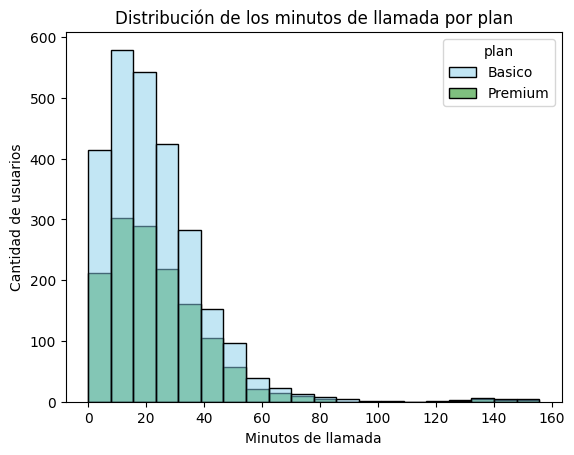

In [58]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], bins=20)
plt.title('Distribución de los minutos de llamada por plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución: fuertemente sesgada a la derecha. La mayoría de los usuarios acumula menos de 50 minutos de llamada, con un pico entre 10 y 20, y una cola larga de pocos usuarios que superan los 100 minutos.
Por plan: Basico y Premium tienen la misma forma y se concentran en los mismos valores. No existe algún patrón claro entre el plan y los minutos de llamada. Premium se ve más bajo solo porque tiene menos usuarios.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

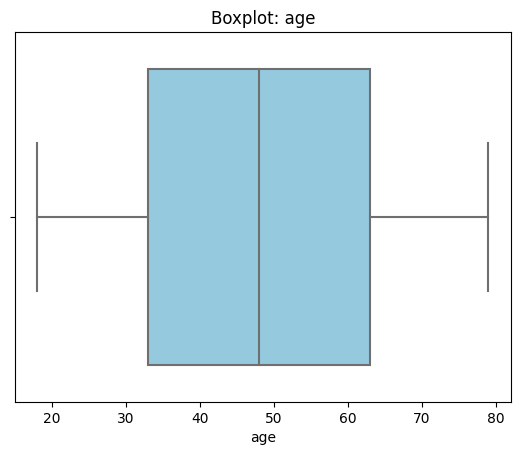

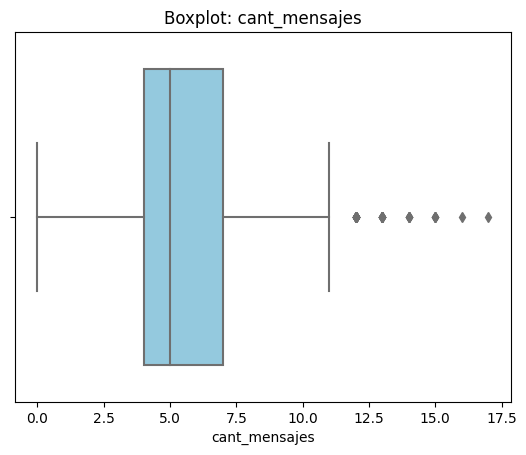

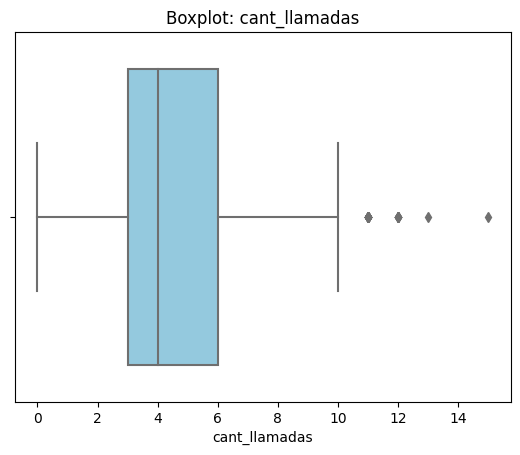

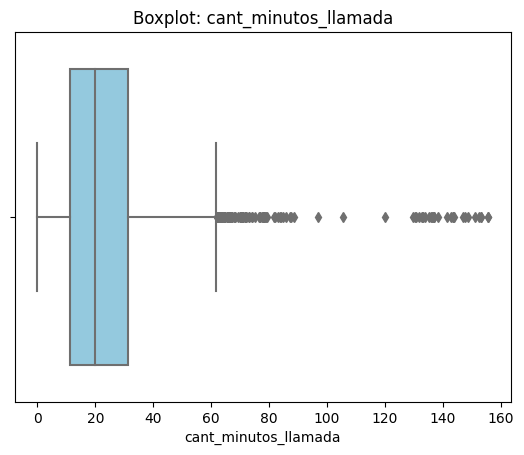

In [59]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:

Age: no presenta outliers. Las edades van de 18 a 79 y los bigotes cubren todo el rango.
cant_mensajes: presenta outliers solo del lado derecho, usuarios con más de ~11 mensajes (hasta 17).
cant_llamadas: presenta outliers solo del lado derecho, usuarios con más de ~11 llamadas (hasta ~17).
cant_minutos_llamada: presenta outliers solo del lado derecho. Son los más numerosos y extremos: desde ~62 hasta ~155 minutos, con un grupo separado alrededor de 130 a 155.

In [60]:

# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(f"{col}: límite superior = {limite_superior:.2f} | "
          f"máximo = {user_profile[col].max()} | "
          f"outliers = {n_outliers} ({n_outliers / len(user_profile):.2%})")




cant_mensajes: límite superior = 11.50 | máximo = 17.0 | outliers = 46 (1.15%)
cant_llamadas: límite superior = 10.50 | máximo = 15.0 | outliers = 30 (0.75%)
cant_minutos_llamada: límite superior = 61.86 | máximo = 155.69 | outliers = 109 (2.73%)


In [61]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 

cant_mensajes: mantener. Hay 46 outliers (1.15%), con un máximo de 17 frente a un límite superior de 11.5. Es una cantidad pequeña y los valores son posibles, no errores de captura. Representan usuarios intensivos.
cant_llamadas: mantener. Hay 30 outliers (0.75%), con un máximo de 15 frente a un límite de 10.5. Es el porcentaje más bajo de los tres y los valores son plausibles.
cant_minutos_llamada: mantener. Hay 109 outliers (2.73%), con un máximo de 155.69 minutos frente a un límite de 61.86. Es la variable con más valores extremos y la media (23.3) queda por encima de la mediana (19.8) por esa cola. Aun así, son minutos acumulados reales, y estos usuarios son los más relevantes para diseñar planes y estrategias de retención. Al reportar tendencias conviene usar la mediana.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [66]:
# Crear columna grupo_uso
import numpy as np

condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
user_profile['grupo_uso'] = np.select(condiciones, ['Bajo uso', 'Uso medio'], default='Alto uso')

In [67]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [68]:
# Crear columna grupo_edad
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]
user_profile['grupo_edad'] = np.select(condiciones_edad, ['Joven', 'Adulto'], default='Adulto Mayor')

In [69]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

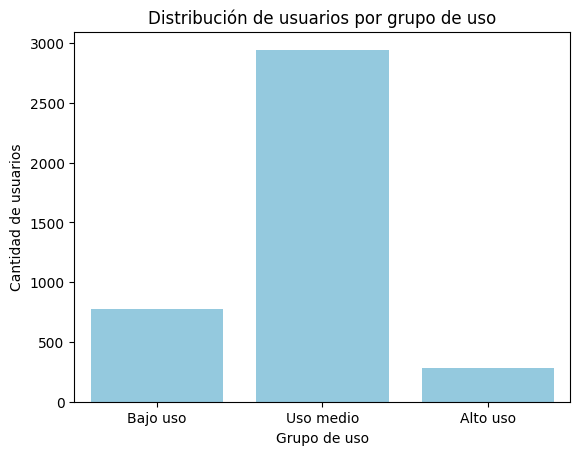

In [70]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

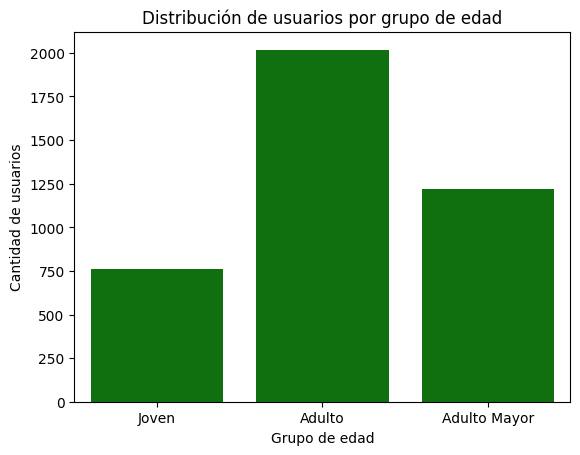

In [71]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='green')
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
¿Qué problemas tenían los datos y qué porcentaje representaban?
age: tenía el sentinel -999 en filas % de 4,000). Distorsionaba la media (33.7 frente a una mediana de 47) y la desviación estándar (123). Se reemplazó por la mediana.
city: 469 nulos (11.72%) y 96 registros con “?” (2.4%). En total 565 filas (14.1%) sin ciudad válida. Se dejaron como nulos, porque no se puede inferir la ciudad.
reg_date: 40 registros (1%) con año 2026, imposible porque los datos llegan hasta 2024. Se marcaron como nulos.
date en usage: 50 nulos (0.12%). Se dejaron como nulos.
duration y length: 55.19% y 44.74% de nulos. No son errores: dependen de type (99.93% de los mensajes no tienen duración y 99.93% de las llamadas no tienen longitud). Se dejaron como nulos.
churn_date: 88.35% de nulos (3,534 filas). Son clientes activos, no un error.
Un usuario sin registros de uso (3,999 de 4,000 tras el merge). Se rellenó con 0 para que no cayera en ‘Alto uso’ por error.
2. ¿Qué segmentos identifiqué y cómo se comportan?
Por edad: Joven (menos de 30, Adulto (30 a 59) y Adulto Mayor (60 o más). Las edades son casi uniformes entre 18 y 79, por eso Adulto es el grupo más grande: cubre el rango más ancho.
Por uso: Bajo uso, Uso medio y Alto uso. En promedio, cada usuario envía 5.5 mensajes, hace 4.5 llamadas y acumula 23.3 minutos (mediana de 19.8).
Por plan: Basico es 64.88% de la base y Premium 35.12%. En los histogramas, ambos planes tienen la misma forma de edad, mensajes, llamadas y minutos. Es decir, el plan no explica el nivel de uso ni la edad.
3. ¿Qué segmentos parecen más valiosos y por qué?
Alto uso: generan más tráfico y tienen más probabilidad de pasarse de lo incluido en su plan y pagar extras. Son los más relevantes para ingresos adicionales y para cuidar la retención.
Premium: pagan más, así que aportan más ingreso por cliente. Pero su uso es igual al de Basico, por lo que hay riesgo de que perciban que no aprovechan lo que pagan.

4. ¿Qué patrones de uso extremo encontré y qué implican?
Mensajes: 46 usuarios (1.15%), con un máximo de 17 frente a un límite superior de 11.5.
Llamadas: 30 usuarios (0.75%), con un máximo de 15 frente a un límite de 10.5.
Minutos de llamada: 109 usuarios (2.73%), con un máximo de 155.69 frente a un límite de 61.86. Hay un grupo separado entre ~130 y ~155 minutos.
Se mantuvieron: son valores posibles, no errores de captura. Implican que existe un grupo pequeño pero muy intensivo, que el plan actual probablemente no atiende bien. Son candidatos a un plan con más minutos y a ofertas de retención. Como inflan el promedio, conviene reportar con la mediana.
5. ¿Qué recomendaciones haría?
Diferenciar mejor Basico y Premium. Si se usan igual, Premium necesita beneficios claros (más minutos o GB, prioridad, extras) que justifiquen su precio.
Crear un plan para usuarios intensivos, con más minutos incluidos, dirigido al ~3% que supera los 62 minutos.
Ofrecer un plan de entrada más económico al segmento de Bajo uso, que no necesita un plan caro.
Lanzar ofertas de retención para Alto uso y para Premium con uso bajo. Para priorizar, usa las tasas de churn por segmento.
Mejorar la captura de datos: evitar sentinels (-999 y “?”) y validar que no se registren fechas futuras.
✍️ **Escribe aquí tu análisis ejecutivo:**


### Análisis ejecutivo

Problemas detectados en los datos
age: tenía el sentinel -999, que distorsionaba la media (33.7 frente a una mediana de 47) y la desviación estándar (123). Se reemplazó por la mediana.
city: 469 nulos (11.72%) y 96 registros con “?” (2.4%). En total 565 filas (14.1%) sin ciudad válida. Se dejaron como nulos.
reg_date: 40 registros (1%) con año 2026, imposible porque los datos llegan hasta 2024. Se marcaron como nulos.
date en usage: 50 nulos (0.12%). Se dejaron como nulos.
duration y length: 55.19% y 44.74% de nulos. No son errores: dependen del tipo de registro (99.93% de los mensajes no tienen duración y 99.93% de las llamadas no tienen longitud). Se dejaron como nulos.
churn_date: 88.35% de nulos (3,534 filas). Corresponde a clientes activos, no es un error.
Usuario sin uso: 1 de los 4,000 usuarios no tenía registros en usage. Se rellenó con 0.
🔍 Segmentos por edad
La edad se distribuye de forma casi uniforme entre 18 y 79 años. Los segmentos son Joven, Adulto y Adulto Mayor.
Adulto es el más grande porque cubre el rango más ancho (30 a 59 años).
La distribución de edad es muy parecida entre Basico y Premium: la edad no determina qué plan elige el cliente.
📊 Segmentos por nivel de uso
La base se divide en Bajo uso, Uso medio y Alto uso.
En promedio, un usuario envía 5.5 mensajes, hace 4.5 llamadas y acumula 23.3 minutos (mediana de 19.8).
Basico representa 64.88% de los clientes y Premium 35.12%. En los histogramas, ambos planes mostraron la misma forma de uso en mensajes, llamadas y minutos.

➡️ Esto sugiere que el plan actual no está segmentando bien a los clientes: usuarios con el mismo comportamiento terminan en planes distintos. Confírmalo con la tabla cruzada de plan y grupo de uso antes de afirmarlo.

💎 Segmentos más valiosos
Alto uso: generan más tráfico y más probabilidad de consumir extras (minutos o GB sobre lo incluido en el plan).
Premium con uso similar a Basico: son clientes que pagan más sin usar más. Eso es valioso en ingresos, pero es un riesgo de churn si perciben que no aprovechan su plan.
📈 Patrones de uso extremo (outliers)
cant_mensajes: 46 usuarios (1.15%), con un máximo de 17 frente a un límite de 11.5.
cant_llamadas: 30 usuarios (0.75%), con un máximo de 15 frente a un límite de 10.5.
cant_minutos_llamada: 109 usuarios (2.73%), con un máximo de 155.69 minutos frente a un límite de 61.86. Hay un grupo separado entre ~130 y ~155 minutos.
Se mantuvieron porque son valores posibles, no errores de captura. Son pocos usuarios, pero muy intensivos, y son los candidatos naturales para planes con más minutos o para ofertas de retención.
💡 Recomendaciones
Rediseñar la diferencia entre planes. Si Basico y Premium se usan igual, Premium necesita beneficios claros (más minutos o GB, prioridad, extras) para justificar su precio.
Crear un plan para usuarios intensivos, con más minutos incluidos, dirigido al ~3% que supera los 62 minutos.
Ofrecer un plan de entrada para el segmento de Bajo uso, que no necesita un plan caro.
Ofertas de retención para Premium con uso bajo y para los usuarios de Alto uso. Para decidir a quiénes, usa las tasas de churn por segmento del código de arriba.
Mejorar la calidad de los datos en origen. Evitar sentinels (-999 y “?”) y validar que no se capturen fechas futuras.
Reportar con la mediana y no con la media, porque la cola de usuarios intensivos infla el promedio. 

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`